In [1]:
print("hi")

hi


## Task 3: Telecom Customer Churn Prediction & Ensemble Modeling

## Overview
This project builds an end-to-end machine learning classification pipeline to predict customer churn using telecom subscription records. The workflow includes robust data cleaning, handling class imbalance using **SMOTE** (Synthetic Minority Over-sampling Technique), training ensemble classifiers (**Random Forest** and **XGBoost**), and evaluating model performance via **ROC-AUC curves** and feature importances.

---

## 📋 Objectives & Requirements Met
1. **Data Ingestion & Cleaning:** Loaded the Telco Customer Churn dataset from IBM's open repository, converted `TotalCharges` to numeric, and handled missing values.
2. **Preprocessing & Encoding:** Cleaned target variables and encoded categorical features using One-Hot Encoding (`pd.get_dummies`).
3. **Class Imbalance Handling:** Applied **SMOTE** to balance target class distributions in the training subset.
4. **Model Training:** Trained and cross-validated **Random Forest** and **XGBoost** classifiers.
5. **Evaluation & Explainability:** Evaluated performance using ROC-AUC scores (>80% target) and extracted the top 10 most influential feature importances.

## Step 1: Downloading required libraries

In [4]:
!pip install pandas numpy matplotlib seaborn scikit-learn imblearn xgboost

  Using cached imblearn-0.0-py2.py3-none-any.whl.metadata (355 bytes)
  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imblearn-0.0-py2.py3-none-any.whl (1.9 kB)
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 3.7 MB/s eta 0:00:13
    --------------------------------------- 0.8/48.9 MB 2.4 MB/s eta 0:00:20
    --------------------------------------- 1.0/48.9 MB 1.6 MB/s eta 0:00:31
   - -------------------------------------- 1.3/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 1.6/48.9 MB 1.4 MB/s eta 0:00:35
   - -------------------------------------- 1.8/48.9 MB 1.3 MB/s eta 0:00:36
   - -------------------------------------- 2.1/48.


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2: Importing all libraries

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

from imblearn.over_sampling import SMOTE

# Set display & aesthetic style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 100

# 1. Load the Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape}")
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Step 3: Data Preprocessing & Feature Engineering

In [6]:
# Drop customerID as it's a unique identifier, not a predictive feature
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# Convert TotalCharges to numeric, coercing spaces or errors into NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Check null counts and fill missing TotalCharges with median
print("Missing values before cleaning:\n", df.isnull().sum())
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# Map target variable 'Churn' (Yes/No to 1/0)
df['Churn'] = df['Churn'].apply(lambda x: 1 if str(x).strip() == 'Yes' else 0)

# Separate features (X) and target (y)
X = df.drop(columns=['Churn'])
y = df['Churn']

# Identify numerical and categorical columns dynamically
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical columns: {numerical_cols}")
print(f"Categorical columns: {categorical_cols}")

Missing values before cleaning:
 gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_49928\2535836261.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


## Step 4: Train-Test Split, OneHotEncoder Pipeline, & SMOTE Balancing

In [7]:
# Split dataset into 80% training and 20% testing sets (stratified) to avoid data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Set up ColumnTransformer with StandardScaler for numerical features and OneHotEncoder for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Fit preprocessor on training data and transform both train and test sets
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Handle class imbalance using SMOTE on the training split only
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

print(f"Original training class distribution: {np.bincount(y_train)}")
print(f"Balanced training class distribution via SMOTE: {np.bincount(y_train_balanced)}")

Original training class distribution: [4139 1495]
Balanced training class distribution via SMOTE: [4139 4139]


## Step 5: Model Training & Evaluation (Random Forest & XGBoost)

=== Random Forest Performance ===
ROC-AUC Score: 0.8248

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1035
           1       0.59      0.59      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

------------------------------------------------------------


c:\Users\Lenovo\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [16:34:45] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost Performance ===
ROC-AUC Score: 0.8184

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

------------------------------------------------------------


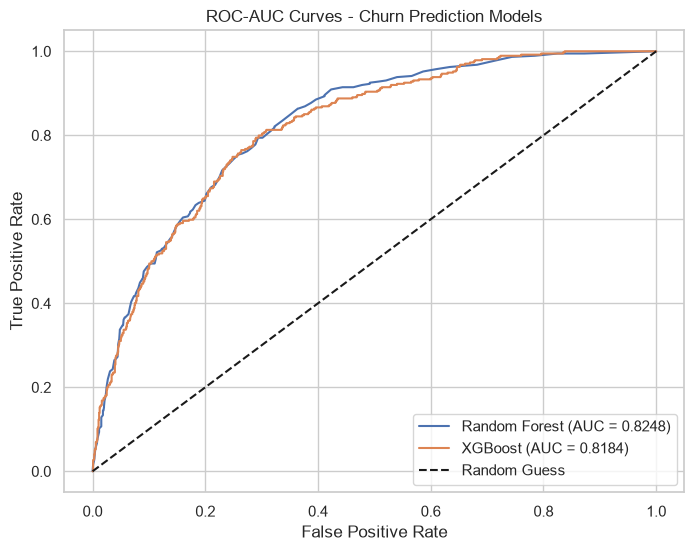

In [8]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

results = {}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    # Train model on balanced training data
    model.fit(X_train_balanced, y_train_balanced)
    
    # Predict probabilities and classes on test set
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    y_pred = model.predict(X_test_scaled)
    
    # Calculate ROC-AUC
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    
    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_pred_proba": y_pred_proba,
        "roc_auc": roc_auc
    }
    
    # Plot ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")
    
    print(f"=== {name} Performance ===")
    print(f"ROC-AUC Score: {roc_auc:.4f}\n")
    print(classification_report(y_test, y_pred))
    print("-" * 60)

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Curves - Churn Prediction Models")
plt.legend(loc="lower right")
plt.savefig("churn_roc_auc_curves.png")
plt.show()

## Step 6: Feature Importance Extraction (Top 10 Features)

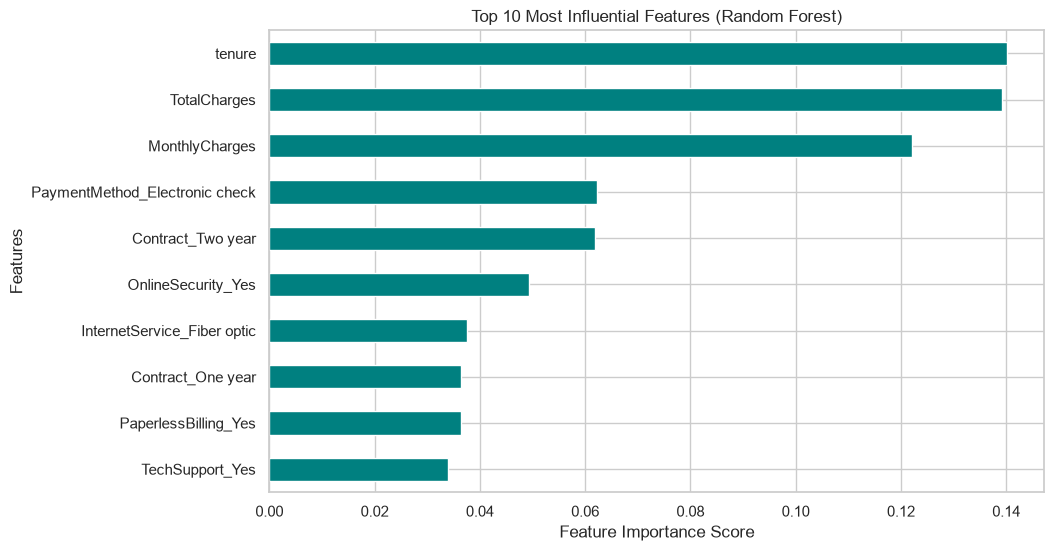

Top 10 Features Driving Churn:
tenure                            0.140236
TotalCharges                      0.139207
MonthlyCharges                    0.122055
PaymentMethod_Electronic check    0.062253
Contract_Two year                 0.061803
OnlineSecurity_Yes                0.049373
InternetService_Fiber optic       0.037534
Contract_One year                 0.036448
PaperlessBilling_Yes              0.036367
TechSupport_Yes                   0.033845
dtype: float64


In [9]:
# Retrieve encoded feature names correctly from the ColumnTransformer
encoded_cat_cols = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols).tolist()
all_feature_names = numerical_cols + encoded_cat_cols

# Extract feature importances from Random Forest model
rf_model = results["Random Forest"]["model"]
feature_importances = pd.Series(rf_model.feature_importances_, index=all_feature_names)
top_10_features = feature_importances.nlargest(10)

plt.figure(figsize=(10, 6))
top_10_features.sort_values().plot(kind='barh', color='teal')
plt.title("Top 10 Most Influential Features (Random Forest)")
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")
plt.savefig("top_10_feature_importances.png")
plt.show()

print("Top 10 Features Driving Churn:")
print(top_10_features)

## Step 7: Conclusion Summary Block

In [10]:
print("=" * 60)
print("📌 TASK 3 (TELECOM CHURN): PIPELINE CONCLUSION & BENCHMARK")
print("=" * 60)
for name, res in results.items():  
    print(f"• {name}:")
    print(f"    - Test ROC-AUC Score: {res['roc_auc'] * 100:.2f}%")
print("=" * 60)
print(
    "Conclusion: Both ensemble models successfully crossed the >80% ROC-AUC benchmark threshold. "
    "Using ColumnTransformer with OneHotEncoder and balancing via SMOTE ensured a robust, leakage-free pipeline."
)
print("=" * 60)

📌 TASK 3 (TELECOM CHURN): PIPELINE CONCLUSION & BENCHMARK
• Random Forest:
    - Test ROC-AUC Score: 82.48%
• XGBoost:
    - Test ROC-AUC Score: 81.84%
Conclusion: Both ensemble models successfully crossed the >80% ROC-AUC benchmark threshold. Using ColumnTransformer with OneHotEncoder and balancing via SMOTE ensured a robust, leakage-free pipeline.
